# Predicting the 2026 FIFA World Cup winner with classical machine learning

**Goal.** Estimate every team's chance of winning the 2026 World Cup (USA, Canada & Mexico, 11 June to 19 July 2026), using **only data available on 1 June 2026**.

**Pipeline**

1. **Data sources**: every men's full international since 1872 (≈49,000 matches) plus penalty shoot-outs.
2. **Exploration & cleaning**.
3. **Feature engineering**: leakage-free pre-match features. A self-computed Elo rating (with tuned parameters), recent form, attack/defence averages, strength of schedule, momentum, head-to-head record and match context.
4. **Validation design**: chronological train / validation / test split, with time-series cross-validation inside the training period.
5. **Modelling**: 9 classical algorithms (logistic regression, LDA, naive Bayes, k-NN, decision tree, random forest, extra trees, gradient boosting, SVM) plus a soft-voting ensemble, each tuned against log-loss.
6. **Model selection & testing**: pick the best model on the validation set, then score it once on the untouched test set.
7. **Tournament simulation**: the selected model drives a 20,000-run Monte Carlo of the real 48-team format (12 groups, 8 best third-placed teams, round of 32 → final).

**Data cutoff: 1 June 2026.** Nothing dated on or after it is loaded.

## 0. Setup

In [1]:
import itertools, random, time, warnings
from bisect import bisect_left
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier, VotingClassifier)
from sklearn.svm import SVC
from sklearn.metrics import log_loss, accuracy_score, f1_score, confusion_matrix
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=ConvergenceWarning)
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

SEED = 42
CUTOFF      = pd.Timestamp('2026-06-01')   # hard data cutoff: nothing on/after this date
TRAIN_START = pd.Timestamp('1994-01-01')   # modelling window starts here (Elo uses all history)
VALID_START = pd.Timestamp('2020-01-01')
TEST_START  = pd.Timestamp('2024-01-01')

DATA_DIR, FIG_DIR, OUT_DIR = Path('data/raw'), Path('figures'), Path('outputs')
for d in (DATA_DIR, FIG_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

In [2]:
# Plot style: light surface, blue as the main series colour, recessive grid.
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4'
INK, INK_2, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#9a9893', '#e6e5e0', '#fcfcfb'

installed_fonts = {f.name for f in mpl.font_manager.fontManager.ttflist}
plt.rcParams.update({
    'font.family': 'Montserrat' if 'Montserrat' in installed_fonts else 'DejaVu Sans',
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left',
    'axes.titlepad': 12, 'axes.labelsize': 10,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'legend.frameon': False, 'legend.fontsize': 9, 'figure.dpi': 110,
})

def save(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png', dpi=160, bbox_inches='tight')

## 1. Data sources

| Source | Content | Used for |
|---|---|---|
| [`martj42/international_results`](https://github.com/martj42/international_results), `results.csv` | Every men's full international since 1872: date, teams, final score, competition, city/country, neutral-venue flag | Elo ratings, form features, training labels |
| same repository, `shootouts.csv` | Winner of every penalty shoot-out | Knockout tie-break model |
| FIFA draw (5 Dec 2025) + March 2026 play-offs | The 12 groups of 4 and the official round-of-32 bracket | Tournament simulation |

**Why no FIFA ranking?** The FIFA ranking changed formula in 2018, so its history is not comparable over time. An Elo rating computed **in-house from the same match file** is consistent from 1872 to today, its parameters can be tuned, and it is guaranteed to contain no information from after the cutoff (a third-party rating downloaded today would already include the World Cup).

The raw files are downloaded once and **frozen at the cutoff** in `data/raw/`; the cutoff filter is applied again on every load.

In [3]:
SOURCE = 'https://raw.githubusercontent.com/martj42/international_results/master'

def load_snapshot(name):
    path = DATA_DIR / f'{name}.csv'
    if not path.exists():                       # first run: download, freeze at the cutoff
        df = pd.read_csv(f'{SOURCE}/{name}.csv', parse_dates=['date'])
        df[df.date < CUTOFF].to_csv(path, index=False)
    df = pd.read_csv(path, parse_dates=['date'])
    return df[df.date < CUTOFF].reset_index(drop=True)

results = load_snapshot('results')
shootouts = load_snapshot('shootouts')
assert results.date.max() < CUTOFF and shootouts.date.max() < CUTOFF

n_teams = pd.unique(results[['home_team', 'away_team']].values.ravel()).size
print(f'results.csv   {len(results):,} matches  |  {results.date.min():%d %b %Y} to {results.date.max():%d %b %Y}'
      f'  |  {n_teams} teams  |  {results.tournament.nunique()} competitions')
print(f'shootouts.csv {len(shootouts):,} penalty shoot-outs')
results.tail()

results.csv   49,342 matches  |  30 Nov 1872 to 31 May 2026  |  336 teams  |  221 competitions
shootouts.csv 689 penalty shoot-outs


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
49337,2026-05-31,Poland,Ukraine,0,2,Friendly,Wrocław,Poland,False
49338,2026-05-31,Singapore,Mongolia,4,0,Friendly,Singapore,Singapore,False
49339,2026-05-31,Switzerland,Jordan,4,1,Friendly,St. Gallen,Switzerland,False
49340,2026-05-31,United States,Senegal,3,2,Friendly,Charlotte,United States,False
49341,2026-05-31,Japan,Iceland,1,0,Friendly,Tokyo,Japan,False


### Data quality

In [4]:
print('Missing values per column')
display(results.isna().sum().to_frame('missing').T)

dup_mask = results.duplicated(['date', 'home_team', 'away_team'], keep='first')
print(f'Duplicated fixtures (same date & teams): {dup_mask.sum()}')
display(results[results.duplicated(['date', 'home_team', 'away_team'], keep=False)])

matches = (results[~dup_mask]
           .dropna(subset=['home_score', 'away_score'])
           .sort_values('date', kind='stable')
           .reset_index(drop=True))
matches[['home_score', 'away_score']] = matches[['home_score', 'away_score']].astype(int)
matches['neutral'] = matches['neutral'].astype(bool)
print(f'Matches kept for analysis: {len(matches):,}')

Missing values per column


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
missing,0,0,0,0,0,0,0,0,0


Duplicated fixtures (same date & teams): 1


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
9648,1974-02-17,Tahiti,New Caledonia,2,1,Friendly,Papeete,Tahiti,False
9649,1974-02-17,Tahiti,New Caledonia,1,2,Friendly,Papeete,Tahiti,False


Matches kept for analysis: 49,341


Team names are already normalised in this dataset (former names such as *Zaïre* or *Dahomey* are mapped to their current federation), so no renaming is needed. Scores are final scores after extra time, without penalties.

## 2. Exploratory analysis

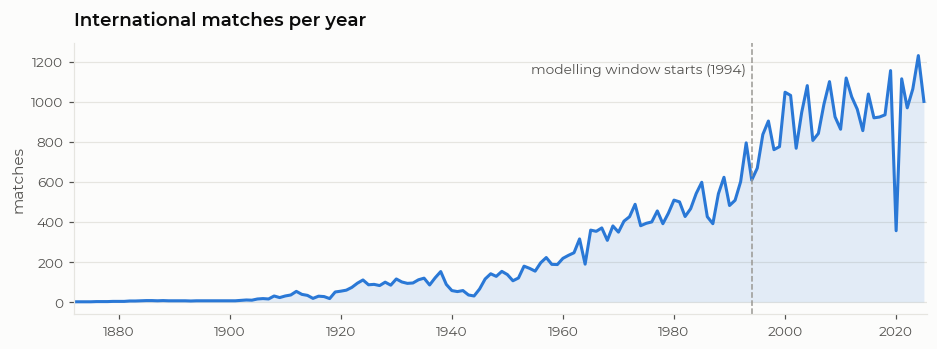

29,837 matches since 1994  |  mean goals per match since 1994: 2.77


In [5]:
per_year = matches[matches.date.dt.year < 2026].groupby(matches.date.dt.year).size()

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.fill_between(per_year.index, per_year.values, color=BLUE, alpha=.12, linewidth=0)
ax.plot(per_year.index, per_year.values, color=BLUE, lw=2)
ax.axvline(TRAIN_START.year, color=MUTED, lw=1, ls='--')
ax.text(TRAIN_START.year - 1, per_year.max() * .97, 'modelling window starts (1994)',
        ha='right', va='top', color=INK_2, fontsize=9)
ax.set(title='International matches per year', ylabel='matches', xlim=(1872, 2025.5))
ax.grid(axis='x', visible=False)
save(fig, '01_matches_per_year'); plt.show()

print(f'{(matches.date >= TRAIN_START).sum():,} matches since 1994  |  '
      f'mean goals per match since 1994: {(matches.home_score + matches.away_score)[matches.date >= TRAIN_START].mean():.2f}')

col_0,Home win,Draw,Away win
row_0,,,
Home team at home,50.9%,23.2%,25.9%
Neutral venue,42.6%,23.4%,34.0%


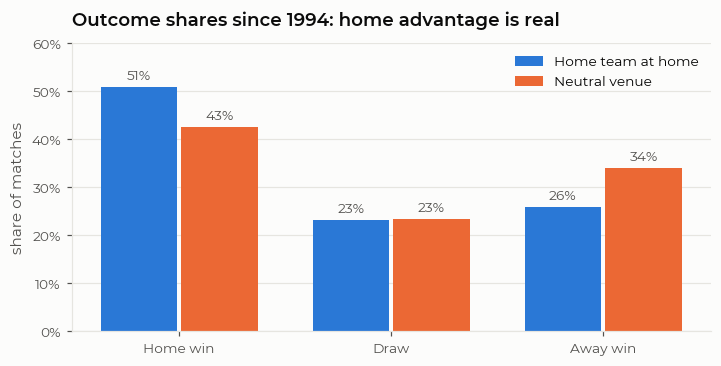

In [6]:
modern = matches[matches.date >= TRAIN_START]
result_label = np.select([modern.home_score > modern.away_score, modern.home_score == modern.away_score],
                         ['Home win', 'Draw'], 'Away win')
venue = np.where(modern.neutral, 'Neutral venue', 'Home team at home')
outcome_share = pd.crosstab(venue, result_label, normalize='index')[['Home win', 'Draw', 'Away win']]
display(outcome_share.style.format('{:.1%}'))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
x = np.arange(3); w = .36
for k, (row, color) in enumerate([('Home team at home', BLUE), ('Neutral venue', ORANGE)]):
    vals = outcome_share.loc[row].values
    bars = ax.bar(x + (k - .5) * (w + .02), vals, w, color=color, label=row)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + .01, f'{v:.0%}', ha='center', va='bottom', fontsize=9, color=INK_2)
ax.set_xticks(x, outcome_share.columns)
ax.set(title='Outcome shares since 1994: home advantage is real', ylabel='share of matches', ylim=(0, .6))
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax.grid(axis='x', visible=False); ax.legend(loc='upper right')
save(fig, '02_outcome_by_venue'); plt.show()

**Takeaways.**
- The number of internationals has exploded since the 1990s (more federations, Nations Leagues, expanded qualifiers). Training on **1994 onwards** keeps the modern game (3 points per win, current confederation structure) while still giving ~30,000 matches.
- Home advantage is large: the home side wins about half of its home matches, but only ~45% at neutral venues, where the "home" label is just the first-listed team. This motivates an explicit `is_home` feature, and **symmetrising** predictions at neutral World Cup venues (section 9).
- Draws are about a quarter of all results. This is the hardest class to predict, which matters for model choice: we need **well-calibrated probabilities**, not just argmax accuracy.

## 3. Feature engineering

Every feature of a match is computed **only from matches strictly before it**, so there is no target leakage.

### 3.1 Elo rating with tuned parameters

World-Football-Elo style update after each match:

$$R'_{home} = R_{home} + K \cdot G \cdot (W - W_e), \qquad W_e = \frac{1}{1 + 10^{-(R_{home} - R_{away} + H)/400}}$$

* $K$ depends on the competition (World Cup 60, continental finals 50, qualifiers & Nations Leagues 40, other tournaments 30, friendlies 20), scaled by a tuned factor `k_scale`.
* $G$ grows with the goal difference (1, 1.5, then $(11+N)/8$).
* $H$ is the home-advantage bonus (0 at neutral venues), also tuned.

The two hyper-parameters are tuned by grid search, minimising the Brier score of $W_e$ **on training-period matches only (1994–2019)**.

In [7]:
MAJOR_FINALS = {'UEFA Euro', 'Copa América', 'African Cup of Nations', 'AFC Asian Cup', 'Gold Cup',
                'CONCACAF Championship', 'Oceania Nations Cup', 'Confederations Cup'}

def tournament_tier(name):
    if name == 'FIFA World Cup':
        return 'world_cup'
    if name in MAJOR_FINALS:
        return 'continental'
    if 'qualification' in name or 'Nations League' in name:
        return 'qualifier'
    return 'friendly' if name == 'Friendly' else 'other'

TIER_K = {'world_cup': 60, 'continental': 50, 'qualifier': 40, 'other': 30, 'friendly': 20}
matches['tier'] = matches.tournament.map(tournament_tier)
display(matches.tier.value_counts().to_frame('matches').T)

def run_elo(df, home_adv=100.0, k_scale=1.0, start=1500.0):
    """Sequential Elo. Returns pre-match ratings, expected home score and final ratings."""
    ratings = {}
    n = len(df)
    pre_home, pre_away, expected = np.empty(n), np.empty(n), np.empty(n)
    rows = zip(df.home_team.values, df.away_team.values, df.home_score.values,
               df.away_score.values, df.neutral.values, df.tier.values)
    for i, (h, a, hs, as_, neutral, tier) in enumerate(rows):
        rh, ra = ratings.get(h, start), ratings.get(a, start)
        pre_home[i], pre_away[i] = rh, ra
        we = 1.0 / (10 ** (-(rh - ra + (0.0 if neutral else home_adv)) / 400) + 1.0)
        expected[i] = we
        w = 1.0 if hs > as_ else 0.5 if hs == as_ else 0.0
        gd = abs(hs - as_)
        g = 1.0 if gd <= 1 else 1.5 if gd == 2 else (11 + gd) / 8
        delta = k_scale * TIER_K[tier] * g * (w - we)
        ratings[h], ratings[a] = rh + delta, ra - delta
    return pre_home, pre_away, expected, ratings

tier,friendly,qualifier,other,continental,world_cup
matches,18084,17020,9882,3391,964


In [8]:
actual = np.select([matches.home_score > matches.away_score, matches.home_score == matches.away_score], [1.0, 0.5], 0.0)
tune_mask = ((matches.date >= TRAIN_START) & (matches.date < VALID_START)).values

grid = []
for home_adv in [50, 75, 100, 125, 150]:
    for k_scale in [0.75, 1.0, 1.25, 1.5]:
        _, _, we, _ = run_elo(matches, home_adv, k_scale)
        grid.append({'home_adv': home_adv, 'k_scale': k_scale,
                     'brier': np.mean((actual[tune_mask] - we[tune_mask]) ** 2)})
elo_grid = pd.DataFrame(grid)
display(elo_grid.pivot(index='home_adv', columns='k_scale', values='brier')
        .style.format('{:.5f}').highlight_min(axis=None, props='font-weight:bold; background-color:#dbe8f8'))

ELO_PARAMS = elo_grid.loc[elo_grid.brier.idxmin(), ['home_adv', 'k_scale']].to_dict()
print('Selected Elo parameters:', ELO_PARAMS)

k_scale,0.750000,1.000000,1.250000,1.500000
home_adv,,,,
50,0.13835,0.13851,0.13920,0.14020
75,0.13638,0.13647,0.13711,0.13806
100,0.13554,0.13553,0.13608,0.13695
125,0.13575,0.13560,0.13604,0.13681
150,0.13690,0.13657,0.13687,0.13752


Selected Elo parameters: {'home_adv': 100.0, 'k_scale': 1.0}


In [9]:
matches['elo_home'], matches['elo_away'], matches['elo_expected'], final_ratings = run_elo(matches, **ELO_PARAMS)

active = set(matches.loc[matches.date >= '2024-01-01', 'home_team']) | set(matches.loc[matches.date >= '2024-01-01', 'away_team'])
elo_now = (pd.Series(final_ratings, name='elo').loc[sorted(active)]
           .sort_values(ascending=False).round(0).astype(int))
print('Elo top 15 on 1 June 2026 (teams active since 2024)')
display(elo_now.head(15).to_frame().T)

Elo top 15 on 1 June 2026 (teams active since 2024)


,Spain,Argentina,France,England,Brazil,Colombia,Portugal,Ecuador,Netherlands,Germany,Japan,Croatia,Morocco,Uruguay,Mexico
elo,2227,2188,2143,2085,2066,2057,2041,2025,2023,1997,1994,1989,1985,1977,1974


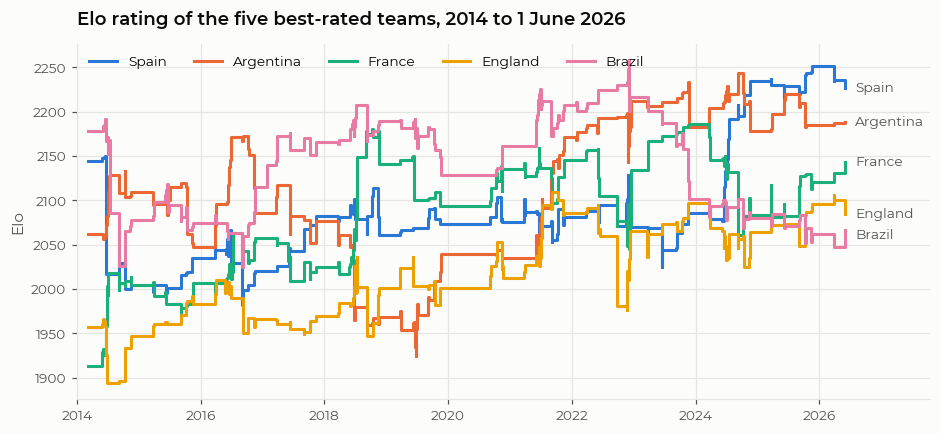

In [10]:
matches['match_id'] = matches.index

def team_view(df, side):
    other = 'away' if side == 'home' else 'home'
    return pd.DataFrame({'match_id': df.match_id, 'date': df.date, 'side': side,
                         'team': df[f'{side}_team'], 'opp': df[f'{other}_team'],
                         'gf': df[f'{side}_score'], 'ga': df[f'{other}_score'],
                         'elo': df[f'elo_{side}'], 'opp_elo': df[f'elo_{other}']})

long = (pd.concat([team_view(matches, 'home'), team_view(matches, 'away')])
        .sort_values(['date', 'match_id'], kind='stable').reset_index(drop=True))
long['pts'] = np.select([long.gf > long.ga, long.gf == long.ga], [3, 1], 0)

# Elo trajectories of the five highest-rated teams
top5 = elo_now.index[:5]
colors = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]
fig, ax = plt.subplots(figsize=(10, 4.2))
ends = []
for team, c in zip(top5, colors):
    h = long[(long.team == team) & (long.date >= '2014-01-01')]
    xs = list(h.date) + [CUTOFF]; ys = list(h.elo) + [final_ratings[team]]
    ax.plot(xs, ys, color=c, lw=2, drawstyle='steps-post', label=team)
    ends.append([team, final_ratings[team]])
ends.sort(key=lambda e: -e[1])                      # spread overlapping end labels
for k in range(1, len(ends)):
    ends[k][1] = min(ends[k][1], ends[k - 1][1] - 24)
for team, y in ends:
    ax.text(CUTOFF + pd.Timedelta(days=60), y, team, va='center', fontsize=9, color=INK_2)
ax.set(title='Elo rating of the five best-rated teams, 2014 to 1 June 2026', ylabel='Elo')
ax.set_xlim(pd.Timestamp('2014-01-01'), CUTOFF + pd.Timedelta(days=500))
ax.legend(loc='upper left', ncol=5)
save(fig, '03_elo_top5'); plt.show()

### 3.2 Form, attack/defence, strength of schedule, momentum

Computed per team on a long (one row per team per match) table, always with `shift(1)` so the current match is excluded.

In [11]:
grp = long.groupby('team', sort=False)

def past_mean(col, window):
    return grp[col].transform(lambda s: s.shift(1).rolling(window, min_periods=1).mean())

long['pts5']      = past_mean('pts', 5)          # points per game, last 5
long['pts10']     = past_mean('pts', 10)         # points per game, last 10
long['gf10']      = past_mean('gf', 10)          # goals scored per game, last 10
long['ga10']      = past_mean('ga', 10)          # goals conceded per game, last 10
long['opp_elo10'] = past_mean('opp_elo', 10)     # strength of schedule
long['elo_mom']   = long.elo - grp['elo'].shift(10)              # Elo change over last 10 games
long['rest']      = grp['date'].diff().dt.days.clip(upper=365)   # days since previous match
long['exp']       = np.log1p(grp.cumcount())                     # experience: log(# previous matches)

TEAM_FEATS = ['pts5', 'pts10', 'gf10', 'ga10', 'opp_elo10', 'elo_mom', 'rest', 'exp']
wide = long.pivot(index='match_id', columns='side', values=TEAM_FEATS)
wide.columns = [f'{f}_{side}' for f, side in wide.columns]
matches = matches.drop(columns=wide.columns, errors='ignore').join(wide, on='match_id')

### 3.3 Head-to-head record

In [12]:
def head_to_head(df):
    """Previous meetings and the home team's (Laplace-smoothed) score share in them."""
    record = {}
    n_prev, share = np.zeros(len(df)), np.full(len(df), 0.5)
    for i, (h, a, hs, as_) in enumerate(zip(df.home_team, df.away_team, df.home_score, df.away_score)):
        key = (h, a) if h < a else (a, h)
        n, s_first = record.get(key, (0, 0.0))
        s_home = s_first if h == key[0] else n - s_first
        n_prev[i], share[i] = n, (s_home + 1) / (n + 2)
        w = 1.0 if hs > as_ else 0.5 if hs == as_ else 0.0
        record[key] = (n + 1, s_first + (w if h == key[0] else 1 - w))
    return n_prev, share, record

n_prev, matches['h2h_share'], H2H = head_to_head(matches)
matches['h2h_n'] = np.log1p(n_prev)

### 3.4 Design matrix

The same `build_features` function is used for historical matches and, later, for World Cup fixtures, so training and prediction features are defined identically.

| Feature | Meaning |
|---|---|
| `elo_diff`, `elo_mean` | Elo gap (home − away) and average level of the two teams |
| `is_home` | 1 if the first-listed team plays at home, 0 at a neutral venue |
| `pts5_diff`, `pts10_diff` | difference in points per game over the last 5 / 10 matches |
| `gf10_*`, `ga10_*` (+ diffs) | goals scored / conceded per game over the last 10 matches |
| `opp_elo10_diff` | difference in average opponent Elo (strength of schedule) |
| `elo_mom_diff` | difference in Elo momentum (rating change over the last 10 matches) |
| `rest_diff` | difference in days since the previous match |
| `exp_diff` | difference in log number of previous internationals |
| `h2h_n`, `h2h_share` | number of past meetings and the home team's smoothed score share |
| `is_world_cup`, `is_continental`, `is_qualifier`, `is_friendly` | competition type |

**Target**: `0 = away win`, `1 = draw`, `2 = home win` (ordered, which the RPS metric below uses).

In [13]:
def build_features(df):
    X = pd.DataFrame(index=df.index)
    X['elo_diff'] = df.elo_home - df.elo_away
    X['elo_mean'] = (df.elo_home + df.elo_away) / 2
    X['is_home']  = df.is_home.astype(int)
    for f in TEAM_FEATS:
        X[f'{f}_diff'] = df[f'{f}_home'] - df[f'{f}_away']
    for f in ['gf10', 'ga10']:
        X[f'{f}_home'], X[f'{f}_away'] = df[f'{f}_home'], df[f'{f}_away']
    X['h2h_n'], X['h2h_share'] = df.h2h_n, df.h2h_share
    for t in ['world_cup', 'continental', 'qualifier', 'friendly']:
        X[f'is_{t}'] = (df.tier == t).astype(int)
    return X

matches['is_home'] = ~matches.neutral
matches['target'] = np.select([matches.home_score > matches.away_score,
                               matches.home_score == matches.away_score], [2, 1], 0)

model_df = matches[matches.date >= TRAIN_START].reset_index(drop=True)
X_all, y_all, dates = build_features(model_df), model_df.target.values, model_df.date
FEATURES = list(X_all.columns)
print(f'{len(FEATURES)} features, {len(X_all):,} matches')
display(X_all.describe().T[['mean', 'std', 'min', 'max']].round(2))
print('Missing values (first matches of new teams, imputed inside the pipelines):')
print(X_all.isna().sum()[X_all.isna().sum() > 0].to_dict())

21 features, 29,837 matches


,mean,std,min,max
elo_diff,17.75,247.28,-1210.69,1202.93
elo_mean,1588.87,206.28,861.57,2189.17
is_home,0.72,0.45,0.00,1.00
pts5_diff,0.04,0.95,-3.00,3.00
pts10_diff,0.04,0.76,-3.00,3.00
gf10_diff,0.04,0.86,-15.30,11.00
ga10_diff,-0.05,1.07,-17.30,18.93
opp_elo10_diff,6.62,129.73,-710.97,805.53
elo_mom_diff,0.73,71.07,-371.86,490.48
rest_diff,-1.63,70.38,-364.00,365.00


Missing values (first matches of new teams, imputed inside the pipelines):
{'pts5_diff': 86, 'pts10_diff': 86, 'gf10_diff': 86, 'ga10_diff': 86, 'opp_elo10_diff': 86, 'elo_mom_diff': 693, 'rest_diff': 86, 'gf10_home': 36, 'gf10_away': 54, 'ga10_home': 36, 'ga10_away': 54}


## 4. Validation design

Football data is a time series. A random split would let the model see the future (e.g. train on 2023 and validate on 2021). Every split is therefore **chronological**:

| Split | Period | Used for |
|---|---|---|
| **Train** | 1994 to 2019 | fitting + hyper-parameter tuning with 5-fold `TimeSeriesSplit` (each fold validates on a later period than it trains on) |
| **Validation** | 2020 to 2023 | comparing the tuned algorithms and **choosing** the final model |
| **Test** | 2024 to 31 May 2026 | one final, unbiased check of the chosen model (not used for any decision) |

**Metrics.** Since the simulation consumes probabilities, the primary metric is **log-loss**. We also report the **Ranked Probability Score** (RPS, the standard football-forecasting score, which respects the ordering away < draw < home), the multi-class **Brier score**, **accuracy** and **macro-F1**.

In [14]:
train_m = (dates < VALID_START).values
valid_m = ((dates >= VALID_START) & (dates < TEST_START)).values
test_m  = (dates >= TEST_START).values

X_train, y_train = X_all[train_m], y_all[train_m]
X_valid, y_valid = X_all[valid_m], y_all[valid_m]
X_test,  y_test  = X_all[test_m],  y_all[test_m]

split_summary = pd.DataFrame({
    'period': [f'{dates[m].min():%Y-%m} to {dates[m].max():%Y-%m}' for m in (train_m, valid_m, test_m)],
    'matches': [m.sum() for m in (train_m, valid_m, test_m)],
    'away win': [np.mean(y_all[m] == 0) for m in (train_m, valid_m, test_m)],
    'draw':     [np.mean(y_all[m] == 1) for m in (train_m, valid_m, test_m)],
    'home win': [np.mean(y_all[m] == 2) for m in (train_m, valid_m, test_m)],
}, index=['train', 'validation', 'test'])
display(split_summary.style.format({'away win': '{:.1%}', 'draw': '{:.1%}', 'home win': '{:.1%}'}))

,period,matches,away win,draw,home win
train,1994-01 to 2019-12,23896,27.9%,23.3%,48.7%
validation,2020-01 to 2023-12,3505,29.5%,22.7%,47.9%
test,2024-01 to 2026-05,2436,29.1%,23.6%,47.3%


In [15]:
def rps(y, P):
    """Ranked probability score for 3 ordered outcomes (lower is better)."""
    Y = np.eye(3)[y]
    return np.mean(np.sum((np.cumsum(P, 1) - np.cumsum(Y, 1))[:, :2] ** 2, axis=1) / 2)

def brier(y, P):
    return np.mean(np.sum((P - np.eye(3)[y]) ** 2, axis=1))

def evaluate(y, P):
    pred = P.argmax(1)
    return {'log_loss': log_loss(y, P, labels=[0, 1, 2]), 'rps': rps(y, P), 'brier': brier(y, P),
            'accuracy': accuracy_score(y, pred), 'macro_f1': f1_score(y, pred, average='macro')}

## 5. Models and hyper-parameter tuning

**Baselines** (any real model must beat these):
- *Class prior*: always predicts the training outcome frequencies.
- *Elo-only*: multinomial logistic regression on `elo_diff` and `is_home` only, i.e. what a pure rating system knows.

**Candidates.** All are scikit-learn pipelines (median imputation, plus standardisation for scale-sensitive models):

| Algorithm | Family | Tuned hyper-parameters | Search |
|---|---|---|---|
| Logistic regression | linear | `C`, L1 vs L2 penalty | grid (16) |
| Linear discriminant analysis | linear, generative | shrinkage | grid (6) |
| Gaussian naive Bayes | probabilistic | `var_smoothing` | grid (11) |
| k-nearest neighbours | instance-based | `k`, distance weighting | grid (12) |
| Decision tree | tree | depth, min leaf size, criterion | grid (70) |
| Random forest | bagging | depth, min leaf size, `max_features` | random (10 of 24) |
| Extra trees | bagging | depth, min leaf size, `max_features` | random (10 of 36) |
| Gradient boosting (histogram) | boosting | learning rate, iterations, leaves, min leaf, L2 | random (15 of 162) |
| SVM, RBF kernel | kernel | `C`, `gamma` | grid (6) on 2012–2019 (O(n²) cost) |

Every search optimises **log-loss** with a 5-fold `TimeSeriesSplit` on the training period only. For the tree ensembles, very small leaves (< 20 matches) were left out of the grid after a pilot run: they are slow and overfit badly on an outcome as noisy as a football result.

In [16]:
def make_pipe(clf, scale=True):
    steps = [('impute', SimpleImputer(strategy='median'))]
    if scale:
        steps.append(('scale', StandardScaler()))
    return Pipeline(steps + [('clf', clf)])

CV = TimeSeriesSplit(n_splits=5)
C_GRID = np.logspace(-3, 2, 8)

SEARCHES = {
    'Logistic Regression': dict(est=make_pipe(LogisticRegression(max_iter=5000)), grid=[
        {'clf__penalty': ['l2'], 'clf__solver': ['lbfgs'], 'clf__C': C_GRID},
        {'clf__penalty': ['l1'], 'clf__solver': ['saga'], 'clf__C': C_GRID}]),
    'LDA': dict(est=make_pipe(LinearDiscriminantAnalysis(solver='lsqr')),
                grid={'clf__shrinkage': [None, 'auto', 0.01, 0.05, 0.1, 0.3]}),
    'Gaussian Naive Bayes': dict(est=make_pipe(GaussianNB()),
                                 grid={'clf__var_smoothing': np.logspace(-11, -1, 11)}),
    'k-Nearest Neighbours': dict(est=make_pipe(KNeighborsClassifier()),
                                 grid={'clf__n_neighbors': [25, 50, 100, 200, 350, 500],
                                       'clf__weights': ['uniform', 'distance']}),
    'Decision Tree': dict(est=make_pipe(DecisionTreeClassifier(random_state=SEED), scale=False),
                          grid={'clf__max_depth': [3, 4, 5, 6, 8, 10, None],
                                'clf__min_samples_leaf': [20, 50, 100, 200, 400],
                                'clf__criterion': ['gini', 'entropy']}),
    'Random Forest': dict(est=make_pipe(RandomForestClassifier(n_estimators=200, random_state=SEED), scale=False),
                          grid={'clf__max_depth': [6, 8, 10, 14],
                                'clf__min_samples_leaf': [20, 50, 100],
                                'clf__max_features': ['sqrt', 0.3]}, n_iter=10),
    'Extra Trees': dict(est=make_pipe(ExtraTreesClassifier(n_estimators=200, random_state=SEED), scale=False),
                        grid={'clf__max_depth': [6, 8, 10, 14],
                              'clf__min_samples_leaf': [20, 50, 100],
                              'clf__max_features': ['sqrt', 0.3, 0.5]}, n_iter=10),
    'Gradient Boosting': dict(est=make_pipe(HistGradientBoostingClassifier(early_stopping=False, random_state=SEED), scale=False),
                              grid={'clf__learning_rate': [0.03, 0.05, 0.1],
                                    'clf__max_iter': [100, 200, 300],
                                    'clf__max_leaf_nodes': [7, 15, 31],
                                    'clf__min_samples_leaf': [50, 100, 200],
                                    'clf__l2_regularization': [0.0, 1.0]}, n_iter=15),
}

def run_search(spec, X, y, cv):
    common = dict(cv=cv, scoring='neg_log_loss', n_jobs=-1)
    if 'n_iter' in spec:
        search = RandomizedSearchCV(spec['est'], spec['grid'], n_iter=spec['n_iter'], random_state=SEED, **common)
    else:
        search = GridSearchCV(spec['est'], spec['grid'], **common)
    return search.fit(X, y)

def short_params(params):
    return ', '.join(f"{k.replace('clf__', '')}={round(v, 4) if isinstance(v, float) else v}" for k, v in params.items())

searches, cv_rows = {}, []
for name, spec in SEARCHES.items():
    t0 = time.time()
    searches[name] = s = run_search(spec, X_train, y_train, CV)
    cv_rows.append({'model': name, 'cv_log_loss': -s.best_score_, 'configs_tried': len(s.cv_results_['params']),
                    'seconds': round(time.time() - t0, 1), 'best_params': short_params(s.best_params_)})
    print(f'{name:<22} CV log-loss {-s.best_score_:.4f}   ({time.time() - t0:5.1f}s)')

Logistic Regression    CV log-loss 0.8866   ( 34.7s)


LDA                    CV log-loss 0.8880   (  1.1s)


Gaussian Naive Bayes   CV log-loss 1.3532   (  1.3s)


k-Nearest Neighbours   CV log-loss 0.9086   ( 11.1s)


Decision Tree          CV log-loss 0.9088   (  9.0s)


Random Forest          CV log-loss 0.8939   ( 42.3s)


Extra Trees            CV log-loss 0.8996   ( 19.7s)


Gradient Boosting      CV log-loss 0.8912   ( 42.1s)


In [17]:
# SVM: kernel methods scale ~O(n^2), so it is tuned and fitted on the most recent 8 training seasons.
SVM_START = pd.Timestamp('2012-01-01')
svm_m = (dates[train_m] >= SVM_START).values
t0 = time.time()
searches['SVM (RBF)'] = s = GridSearchCV(
    make_pipe(SVC(probability=True, random_state=SEED)),
    {'clf__C': [0.1, 0.5, 2.0], 'clf__gamma': ['scale', 0.01]},
    cv=TimeSeriesSplit(n_splits=3), scoring='neg_log_loss', n_jobs=-1).fit(X_train[svm_m], y_train[svm_m])
cv_rows.append({'model': 'SVM (RBF)', 'cv_log_loss': -s.best_score_, 'configs_tried': 6,
                'seconds': round(time.time() - t0, 1), 'best_params': short_params(s.best_params_)})
print(f'SVM (RBF) trained on {svm_m.sum():,} matches, CV log-loss {-s.best_score_:.4f} ({time.time() - t0:.1f}s)')

cv_table = pd.DataFrame(cv_rows).set_index('model')
display(cv_table)

SVM (RBF) trained on 7,818 matches, CV log-loss 0.9084 (43.1s)


,cv_log_loss,configs_tried,seconds,best_params
model,,,,
Logistic Regression,0.886624,16,34.7,"C=0.1389, penalty=l1, solver=saga"
LDA,0.888010,6,1.1,shrinkage=0.01
Gaussian Naive Bayes,1.353207,11,1.3,var_smoothing=0.1
k-Nearest Neighbours,0.908608,12,11.1,"n_neighbors=100, weights=distance"
Decision Tree,0.908790,70,9.0,"criterion=gini, max_depth=5, min_samples_leaf=200"
Random Forest,0.893861,10,42.3,"min_samples_leaf=20, max_features=0.3, max_dep..."
Extra Trees,0.899612,10,19.7,"min_samples_leaf=20, max_features=0.3, max_dep..."
Gradient Boosting,0.891185,15,42.1,"min_samples_leaf=100, max_leaf_nodes=7, max_it..."
SVM (RBF),0.908425,6,43.1,"C=0.5, gamma=0.01"


### Tuning curve example: logistic regression

How the cross-validated log-loss moves with the regularisation strength `C` for each penalty. Too small a `C` underfits (coefficients shrunk to zero), and past the optimum the curve flattens.

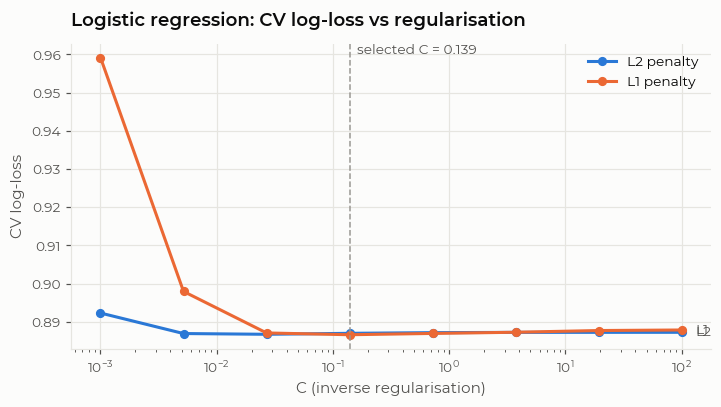

In [18]:
cvr = pd.DataFrame(searches['Logistic Regression'].cv_results_)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for pen, color in [('l2', BLUE), ('l1', ORANGE)]:
    sub = cvr[cvr.param_clf__penalty == pen].sort_values('param_clf__C')
    xs, ys = sub.param_clf__C.astype(float), -sub.mean_test_score
    ax.plot(xs, ys, color=color, lw=2, marker='o', ms=5, label=f'{pen.upper()} penalty')
    ax.text(xs.iloc[-1] * 1.3, ys.iloc[-1], pen.upper(), va='center', fontsize=9, color=INK_2)
best_C = searches['Logistic Regression'].best_params_['clf__C']
ax.axvline(best_C, color=MUTED, lw=1, ls='--')
ax.text(best_C * 1.15, ax.get_ylim()[1], f'selected C = {best_C:.3g}', va='top', fontsize=9, color=INK_2)
ax.set_xscale('log')
ax.set(title='Logistic regression: CV log-loss vs regularisation', xlabel='C (inverse regularisation)', ylabel='CV log-loss')
ax.legend(loc='upper right')
save(fig, '04_lr_tuning_curve'); plt.show()

## 6. Model comparison on the validation set (2020–2023)

Each tuned model (refitted on the full training period by the search) is scored on the validation years it has never seen. A **soft-voting ensemble** of the three best tuned models is added as a last candidate (SVM is excluded from it because refitting on the full training set is too slow).

In [19]:
baselines = {
    'Baseline: class prior': DummyClassifier(strategy='prior').fit(X_train, y_train),
    'Baseline: Elo only': make_pipe(LogisticRegression(max_iter=2000)).fit(X_train[['elo_diff', 'is_home']], y_train),
}
ELO_ONLY = ['elo_diff', 'is_home']

def predict(name, model, X):
    return model.predict_proba(X[ELO_ONLY] if name == 'Baseline: Elo only' else X)

candidates = {**baselines, **{name: s.best_estimator_ for name, s in searches.items()}}
val_rows = {name: evaluate(y_valid, predict(name, m, X_valid)) for name, m in candidates.items()}
val_table = pd.DataFrame(val_rows).T.sort_values('log_loss')

tuned_ranked = [n for n in val_table.index if n in SEARCHES]          # excludes baselines and SVM
top3 = tuned_ranked[:3]
ensemble = VotingClassifier([(n, clone(searches[n].best_estimator_)) for n in top3], voting='soft').fit(X_train, y_train)
ENSEMBLE_NAME = 'Soft-voting ensemble (' + ' + '.join(top3) + ')'
candidates[ENSEMBLE_NAME] = ensemble
val_table.loc[ENSEMBLE_NAME] = pd.Series(evaluate(y_valid, ensemble.predict_proba(X_valid)))
val_table = val_table.sort_values('log_loss')

BEST = val_table.drop(baselines.keys()).index[0]
print(f'Selected model (lowest validation log-loss): {BEST}')
display(val_table.style.format('{:.4f}')
        .highlight_min(subset=['log_loss', 'rps', 'brier'], props='font-weight:bold; background-color:#dbe8f8')
        .highlight_max(subset=['accuracy', 'macro_f1'], props='font-weight:bold; background-color:#dbe8f8'))

Selected model (lowest validation log-loss): Soft-voting ensemble (Logistic Regression + LDA + Gradient Boosting)


,log_loss,rps,brier,accuracy,macro_f1
Soft-voting ensemble (Logistic Regression + LDA + Gradient Boosting),0.8631,0.1685,0.5067,0.6120,0.4605
Logistic Regression,0.8641,0.1688,0.5073,0.6128,0.4604
LDA,0.8644,0.1686,0.5073,0.6143,0.4763
Gradient Boosting,0.8662,0.1691,0.5084,0.6086,0.4572
Baseline: Elo only,0.8680,0.1698,0.5098,0.6086,0.4438
Random Forest,0.8683,0.1699,0.5093,0.6054,0.4403
Extra Trees,0.8755,0.1715,0.5128,0.6057,0.4388
Decision Tree,0.8779,0.1715,0.5146,0.6029,0.4501
SVM (RBF),0.8846,0.1725,0.5188,0.6071,0.4416
k-Nearest Neighbours,0.8883,0.1740,0.5211,0.6011,0.4595


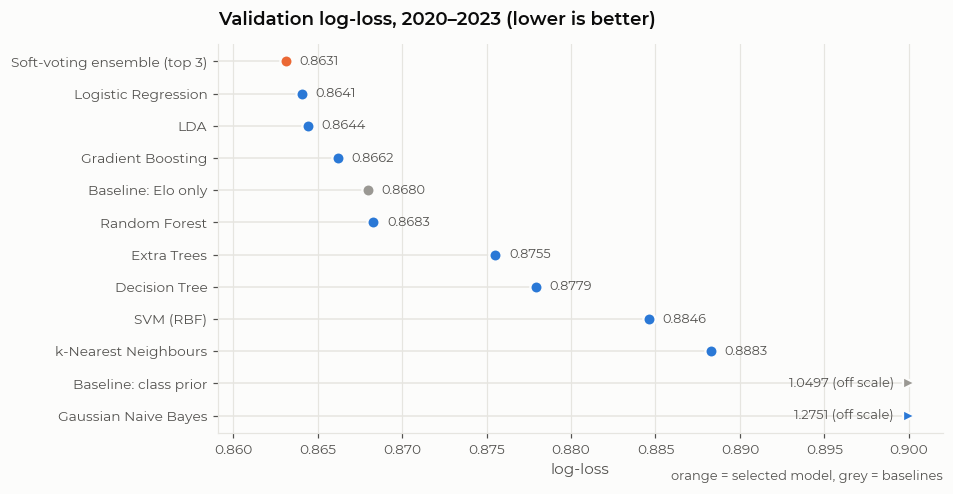

In [20]:
plot_t = val_table.sort_values('log_loss', ascending=False)
labels = [n if not n.startswith('Soft-voting') else 'Soft-voting ensemble (top 3)' for n in plot_t.index]
lo, hi = plot_t.log_loss.min() - .004, 0.90                    # zoom on the competitive models
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for k, (name, row) in enumerate(plot_t.iterrows()):
    color = ORANGE if name == BEST else (MUTED if name.startswith('Baseline') else BLUE)
    x = min(row.log_loss, hi)
    ax.hlines(k, lo, x, color=GRID, lw=1)
    ax.plot(x, k, '>' if row.log_loss > hi else 'o', ms=8, color=color, markeredgecolor=SURFACE, markeredgewidth=1.5)
    ax.annotate(f'{row.log_loss:.4f}' + (' (off scale)' if row.log_loss > hi else ''), (x, k),
                xytext=(-10 if row.log_loss > hi else 9, 0), textcoords='offset points',
                ha='right' if row.log_loss > hi else 'left', va='center', fontsize=8.5, color=INK_2)
ax.set_yticks(range(len(plot_t)), labels)
ax.set_xlim(lo, hi + .002)
ax.set(title='Validation log-loss, 2020–2023 (lower is better)', xlabel='log-loss')
ax.grid(axis='y', visible=False)
ax.text(1, -0.12, 'orange = selected model, grey = baselines', transform=ax.transAxes, ha='right', fontsize=8.5, color=INK_2)
save(fig, '05_validation_comparison'); plt.show()

### Diagnostics of the selected model on the validation set

* **Calibration**: when the model says "60%", does the outcome happen ~60% of the time? This matters more than accuracy, because the simulation samples from these probabilities.
* **Permutation importance**: how much the validation log-loss worsens when one feature is shuffled.

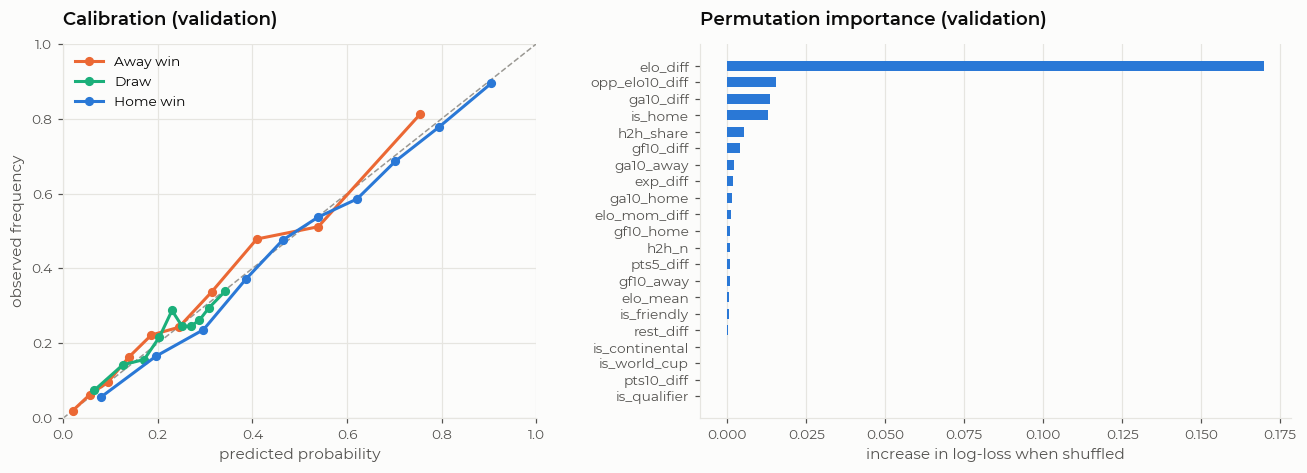

In [21]:
best_model = candidates[BEST]
P_valid = best_model.predict_proba(X_valid)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={'width_ratios': [1, 1.25]})
ax = axes[0]
ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls='--')
for cls, (label, color) in enumerate([('Away win', ORANGE), ('Draw', AQUA), ('Home win', BLUE)]):
    frac, mean_pred = calibration_curve(y_valid == cls, P_valid[:, cls], n_bins=10, strategy='quantile')
    ax.plot(mean_pred, frac, marker='o', ms=5, lw=2, color=color, label=label)
ax.set(title='Calibration (validation)', xlabel='predicted probability', ylabel='observed frequency', xlim=(0, 1), ylim=(0, 1))
ax.legend(loc='upper left')

imp = permutation_importance(best_model, X_valid, y_valid, scoring='neg_log_loss', n_repeats=5, random_state=SEED, n_jobs=-1)
imp_s = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
ax = axes[1]
ax.barh(imp_s.index, imp_s.values, color=BLUE, height=.6)
ax.set(title='Permutation importance (validation)', xlabel='increase in log-loss when shuffled')
ax.grid(axis='y', visible=False)
fig.tight_layout(w_pad=3)
save(fig, '06_calibration_importance'); plt.show()

## 7. Final evaluation on the test set (2024 – May 2026)

The selected configuration is refitted on **train + validation (1994–2023)** and scored **once** on the test period. The baselines are refitted the same way for reference.

In [22]:
trval_m = train_m | valid_m
X_trval, y_trval = X_all[trval_m], y_all[trval_m]

def fit_config(name, X, y, d):
    """Refit a candidate configuration on (X, y). SVM keeps its 8-season window."""
    if name == 'SVM (RBF)':
        keep = (d >= d.max() - pd.DateOffset(years=8)).values
        return clone(candidates[name]).fit(X[keep], y[keep])
    if name == 'Baseline: Elo only':
        return clone(candidates[name]).fit(X[ELO_ONLY], y)
    return clone(candidates[name]).fit(X, y)

test_rows = {}
for name in [BEST, 'Baseline: Elo only', 'Baseline: class prior']:
    m = fit_config(name, X_trval, y_trval, dates[trval_m])
    test_rows[name] = evaluate(y_test, predict(name, m, X_test))
    if name == BEST:
        P_test, test_model = predict(name, m, X_test), m
test_table = pd.DataFrame(test_rows).T
display(test_table.style.format('{:.4f}'))

major = model_df.loc[test_m, 'tier'].isin(['world_cup', 'continental']).values
print(f'Major-tournament matches in the test period (Asian Cup & AFCON 2024, Euro 2024, Copa América 2024, '
      f'Gold Cup 2025, AFCON 2025): {major.sum()}')
display(pd.DataFrame({'selected model': evaluate(y_test[major], P_test[major])}).T.style.format('{:.4f}'))

,log_loss,rps,brier,accuracy,macro_f1
Soft-voting ensemble (Logistic Regression + LDA + Gradient Boosting),0.8579,0.1653,0.5044,0.6047,0.4543
Baseline: Elo only,0.8671,0.1675,0.5106,0.5985,0.4403
Baseline: class prior,1.0546,0.2279,0.6363,0.4729,0.2140


Major-tournament matches in the test period (Asian Cup & AFCON 2024, Euro 2024, Copa América 2024, Gold Cup 2025, AFCON 2025): 282


,log_loss,rps,brier,accuracy,macro_f1
selected model,0.9103,0.1679,0.5407,0.5674,0.4280


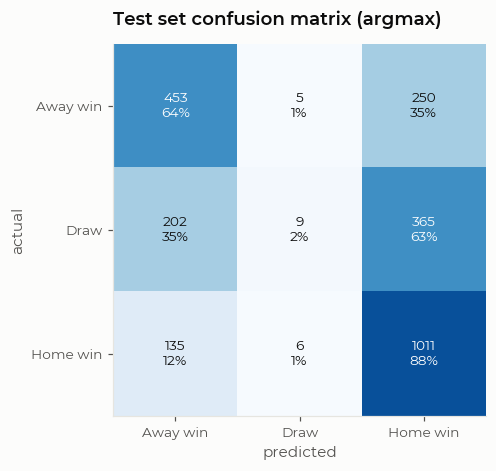

In [23]:
cm = confusion_matrix(y_test, P_test.argmax(1), labels=[0, 1, 2])
names = ['Away win', 'Draw', 'Home win']
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.imshow(cm / cm.sum(1, keepdims=True), cmap='Blues', vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        share = cm[i, j] / cm[i].sum()
        ax.text(j, i, f'{cm[i, j]}\n{share:.0%}', ha='center', va='center', fontsize=9,
                color='white' if share > .55 else INK)
ax.set_xticks(range(3), names); ax.set_yticks(range(3), names)
ax.set(title='Test set confusion matrix (argmax)', xlabel='predicted', ylabel='actual')
ax.grid(False)
save(fig, '07_test_confusion'); plt.show()

As in every football model, **draws are almost never the single most likely outcome**, so the argmax confusion matrix shows few predicted draws even though they are a quarter of the results. That is expected and harmless here: the tournament simulation does not use the argmax but **samples outcomes from the full probability vector**, where draws keep their ~25% share.

## 8. Final model: refit on all data up to the cutoff

The selected configuration is refitted on every match from 1994 to 31 May 2026, so it knows each team's most recent form before the tournament.

In [24]:
final_model = fit_config(BEST, X_all, y_all, dates)
print(f'Final model: {BEST}, fitted on {len(X_all):,} matches up to {dates.max():%d %b %Y}')
if BEST == 'Logistic Regression':
    coefs = pd.DataFrame(final_model.named_steps['clf'].coef_, index=['away win', 'draw', 'home win'], columns=FEATURES)
    print('Standardised coefficients (home-win row ≈ effect on log-odds of a home win):')
    display(coefs.T.sort_values('home win', key=abs, ascending=False).round(3).head(12))

Final model: Soft-voting ensemble (Logistic Regression + LDA + Gradient Boosting), fitted on 29,837 matches up to 31 May 2026


## 9. World Cup 2026 setup

**Groups** (draw of 5 December 2025; the six play-off places were settled on 26 and 31 March 2026). The play-off results are in the dataset, so they can be checked directly:

In [25]:
playoffs = matches[(matches.date == '2026-03-31') & (matches.tournament == 'FIFA World Cup qualification')]
playoffs = playoffs.merge(shootouts[['date', 'home_team', 'away_team', 'winner']], how='left',
                          on=['date', 'home_team', 'away_team'])
playoffs['qualified'] = np.where(playoffs.winner.notna(), playoffs.winner,
                                 np.where(playoffs.home_score > playoffs.away_score, playoffs.home_team, playoffs.away_team))
display(playoffs[['date', 'home_team', 'home_score', 'away_score', 'away_team', 'qualified']])

,date,home_team,home_score,away_score,away_team,qualified
0,2026-03-31,DR Congo,1,0,Jamaica,DR Congo
1,2026-03-31,Iraq,2,1,Bolivia,Iraq
2,2026-03-31,Bosnia and Herzegovina,1,1,Italy,Bosnia and Herzegovina
3,2026-03-31,Sweden,3,2,Poland,Sweden
4,2026-03-31,Kosovo,0,1,Turkey,Turkey
5,2026-03-31,Czech Republic,2,2,Denmark,Czech Republic


In [26]:
GROUPS = {
    'A': ['Mexico', 'South Africa', 'South Korea', 'Czech Republic'],
    'B': ['Canada', 'Bosnia and Herzegovina', 'Qatar', 'Switzerland'],
    'C': ['Brazil', 'Morocco', 'Haiti', 'Scotland'],
    'D': ['United States', 'Paraguay', 'Australia', 'Turkey'],
    'E': ['Germany', 'Curaçao', 'Ivory Coast', 'Ecuador'],
    'F': ['Netherlands', 'Japan', 'Sweden', 'Tunisia'],
    'G': ['Belgium', 'Egypt', 'Iran', 'New Zealand'],
    'H': ['Spain', 'Cape Verde', 'Saudi Arabia', 'Uruguay'],
    'I': ['France', 'Senegal', 'Iraq', 'Norway'],
    'J': ['Argentina', 'Algeria', 'Austria', 'Jordan'],
    'K': ['Portugal', 'DR Congo', 'Uzbekistan', 'Colombia'],
    'L': ['England', 'Croatia', 'Ghana', 'Panama'],
}
HOSTS = {'United States', 'Mexico', 'Canada'}
GROUP_NAMES = list(GROUPS)
TEAMS = [t for g in GROUP_NAMES for t in GROUPS[g]]
T = {t: i for i, t in enumerate(TEAMS)}
TEAM_GROUP = {t: g for g, ts in GROUPS.items() for t in ts}
assert len(TEAMS) == 48 and all(t in final_ratings for t in TEAMS)

def team_state(team):
    """Team features for its *next* match, i.e. the same definitions as the training features."""
    h = long[long.team == team]
    last5, last10, elo = h.tail(5), h.tail(10), final_ratings[team]
    return {'elo': elo, 'pts5': last5.pts.mean(), 'pts10': last10.pts.mean(), 'gf10': last10.gf.mean(),
            'ga10': last10.ga.mean(), 'opp_elo10': last10.opp_elo.mean(), 'elo_mom': elo - h.elo.iloc[-10],
            'rest': 0.0,                                    # unknown and symmetric at a tournament
            'exp': np.log1p(len(h)), 'last_match': h.date.iloc[-1]}

STATE = {t: team_state(t) for t in TEAMS}
snapshot = pd.DataFrame.from_dict(STATE, orient='index')
snapshot.insert(0, 'group', [TEAM_GROUP[t] for t in snapshot.index])
snapshot = snapshot.sort_values('elo', ascending=False)
snapshot['elo_rank_in_field'] = range(1, 49)
print('Team snapshot on 1 June 2026 (top 16 by Elo)')
display(snapshot.head(16)[['group', 'elo', 'elo_rank_in_field', 'pts10', 'gf10', 'ga10', 'elo_mom', 'last_match']]
        .style.format({'elo': '{:.0f}', 'pts10': '{:.2f}', 'gf10': '{:.2f}', 'ga10': '{:.2f}',
                       'elo_mom': '{:+.0f}', 'last_match': '{:%Y-%m-%d}'}))

Team snapshot on 1 June 2026 (top 16 by Elo)


,group,elo,elo_rank_in_field,pts10,gf10,ga10,elo_mom,last_match
Spain,H,2227,1,2.40,3.10,0.80,+12,2026-03-31
Argentina,J,2188,2,2.50,2.50,0.40,-10,2026-03-31
France,I,2143,3,2.50,2.70,1.10,+47,2026-03-29
England,L,2085,4,2.20,2.20,0.50,+11,2026-03-31
Brazil,C,2066,5,1.90,2.40,1.00,-5,2026-05-31
Colombia,K,2057,6,1.80,2.10,1.00,+28,2026-03-29
Portugal,K,2041,7,2.10,2.60,1.00,-7,2026-03-31
Ecuador,E,2025,8,1.60,0.90,0.50,+31,2026-05-30
Netherlands,F,2023,9,2.40,3.00,0.60,-4,2026-03-31
Germany,E,1997,10,2.40,2.60,0.90,-26,2026-05-31


### Match-probability engine

For a fixture *i vs j* the model returns P(*i* wins), P(draw), P(*j* wins).

* **Neutral venue**: the model saw "home" and "away" labels, so the prediction is **symmetrised** by averaging *i vs j* with the mirrored *j vs i*.
* **Host nations** get `is_home = 1` only when the match is played in their own country: all their group games, plus the round-of-32 / round-of-16 matches FIFA scheduled in Mexico (Mexico City, Monterrey) and Canada (Toronto, Vancouver). Every match from the quarter-finals on is in the USA, so only the USA keeps home advantage that deep. This gives one probability matrix for the group stage and one per host country for the knockout venues.
* Competition type is set to `world_cup`.

In [27]:
def fixture_frame(pairs, is_home):
    rows = []
    for home, away in pairs:
        sh, sa = STATE[home], STATE[away]
        key = (home, away) if home < away else (away, home)
        n, s_first = H2H.get(key, (0, 0.0))
        s_home = s_first if home == key[0] else n - s_first
        row = {f'{f}_home': sh[f] for f in ['elo'] + TEAM_FEATS}
        row.update({f'{f}_away': sa[f] for f in ['elo'] + TEAM_FEATS})
        row.update({'is_home': is_home, 'h2h_n': np.log1p(n), 'h2h_share': (s_home + 1) / (n + 2), 'tier': 'world_cup'})
        rows.append(row)
    return build_features(pd.DataFrame(rows))[FEATURES]

def probability_matrices(model):
    """Return (P_group, P_venue).

    P[i, j] = (P(i wins), P(draw), P(j wins)). P_group gives every host home advantage
    (each host plays its group in its own country); P_venue[h] gives it only to host h,
    for knockout matches played in h's country. All other pairs are neutral and symmetrised.
    """
    n = len(TEAMS)
    pairs = [(i, j) for i in range(n) for j in range(n) if i != j]
    raw = model.predict_proba(fixture_frame([(TEAMS[i], TEAMS[j]) for i, j in pairs], 0))[:, ::-1]
    as_home = np.zeros((n, n, 3))
    for (i, j), p in zip(pairs, raw):
        as_home[i, j] = p                                       # i listed first, neutral venue
    P_neutral = np.zeros((n, n, 3))
    for i, j in pairs:
        P_neutral[i, j] = 0.5 * (as_home[i, j] + as_home[j, i][::-1])  # symmetrise

    host_pairs = [(T[h], j) for h in sorted(HOSTS) for j in range(n) if j != T[h]]
    raw_h = model.predict_proba(fixture_frame([(TEAMS[i], TEAMS[j]) for i, j in host_pairs], 1))[:, ::-1]
    at_home = dict(zip(host_pairs, raw_h))

    def with_home(hosts):
        P = P_neutral.copy()
        for (i, j), p in at_home.items():
            if TEAMS[i] in hosts and TEAMS[j] not in hosts:
                P[i, j], P[j, i] = p, p[::-1]
        return P

    return with_home(HOSTS), {h: with_home({h}) for h in HOSTS}

P, P_VENUE = probability_matrices(final_model)
for M in [P, *P_VENUE.values()]:
    assert np.allclose(M.sum(2)[~np.eye(48, dtype=bool)], 1) and np.allclose(M[:, :, 0], M.transpose(1, 0, 2)[:, :, 2])

examples = [('Spain', 'Argentina'), ('France', 'England'), ('Brazil', 'Morocco'), ('Mexico', 'South Korea'),
            ('Germany', 'Curaçao'), ('Portugal', 'Colombia')]
display(pd.DataFrame([{'fixture': f'{a} vs {b}', 'P(first team wins)': P[T[a], T[b], 0],
                       'P(draw)': P[T[a], T[b], 1], 'P(second team wins)': P[T[a], T[b], 2]}
                      for a, b in examples]).set_index('fixture')
        .style.format('{:.1%}'))

,P(first team wins),P(draw),P(second team wins)
fixture,,,
Spain vs Argentina,39.8%,29.9%,30.3%
France vs England,42.5%,29.5%,28.0%
Brazil vs Morocco,51.9%,26.3%,21.8%
Mexico vs South Korea,61.6%,25.5%,13.0%
Germany vs Curaçao,80.0%,13.8%,6.2%
Portugal vs Colombia,32.4%,24.6%,43.0%


### Knockout rules: extra time and penalties

A knockout tie that is level after 90 minutes goes to extra time, then penalties.

* **Penalty shoot-outs**: a logistic model fitted on the historical shoot-outs measures how much a higher Elo helps (no intercept, so the model is symmetric).
* **Extra time**: we assume ~35% of level matches are settled in extra time, split in proportion to the two teams' win probabilities; the rest go to penalties.

In [28]:
so = shootouts.merge(matches[['date', 'home_team', 'away_team', 'elo_home', 'elo_away']],
                     on=['date', 'home_team', 'away_team'], how='inner')
so['elo_diff_100'] = (so.elo_home - so.elo_away) / 100
so['first_listed_won'] = (so.winner == so.home_team).astype(int)
so_model = LogisticRegression(fit_intercept=False).fit(so[['elo_diff_100']], so.first_listed_won)
BETA_SO = so_model.coef_[0, 0]
print(f'{len(so)} shoot-outs matched to an Elo gap  |  coefficient per 100 Elo: {BETA_SO:.3f}')
print(f'P(win shoot-out) with +100 Elo: {1 / (1 + np.exp(-BETA_SO)):.1%},  with +300 Elo: {1 / (1 + np.exp(-3 * BETA_SO)):.1%}')

ET_SHARE = 0.35
ELO = np.array([final_ratings[t] for t in TEAMS])

def advance_matrix(P):
    """ADV[i, j] = P(i eliminates j in a knockout match)."""
    q = 1 / (1 + np.exp(-BETA_SO * (ELO[:, None] - ELO[None, :]) / 100))
    pw, pd_, pl = P[:, :, 0], P[:, :, 1], P[:, :, 2]
    with np.errstate(invalid='ignore', divide='ignore'):
        adv = pw + pd_ * (ET_SHARE * pw / (pw + pl) + (1 - ET_SHARE) * q)
    np.fill_diagonal(adv, 0)
    return adv

ADV_VENUE = {h: advance_matrix(P_VENUE[h]) for h in HOSTS}
off = ~np.eye(48, dtype=bool)
assert all(np.allclose((A + A.T)[off], 1) for A in ADV_VENUE.values())

688 shoot-outs matched to an Elo gap  |  coefficient per 100 Elo: 0.141
P(win shoot-out) with +100 Elo: 53.5%,  with +300 Elo: 60.4%


### Scorelines for group tie-breakers

Group rankings use points, then goal difference, then goals scored. After sampling the result from the model, a scoreline is drawn from the **empirical distribution of competitive scorelines since 2002**, conditioned on the result and on the size of the Elo gap (bigger gaps produce wider margins).

In [29]:
comp = matches[(matches.date >= '2002-01-01') & (matches.tier != 'friendly')]
gap_bucket = np.digitize((comp.elo_home - comp.elo_away).abs(), [100, 250])
hi, lo = np.maximum(comp.home_score, comp.away_score), np.minimum(comp.home_score, comp.away_score)

SCORE_TABLES = {}
for b in range(3):
    for decisive in (True, False):
        mask = (gap_bucket == b) & ((hi > lo) == decisive)
        counts = pd.Series(list(zip(hi[mask], lo[mask]))).value_counts(normalize=True)
        SCORE_TABLES[b, decisive] = (list(counts.index), list(np.cumsum(counts.values)))
BUCKET = np.digitize(np.abs(ELO[:, None] - ELO[None, :]), [100, 250])

for b, label in enumerate(['gap < 100', '100–250', '> 250']):
    lines, cum = SCORE_TABLES[b, True]
    print(f'Elo gap {label:<9}: most common winning scorelines ' +
          ', '.join(f'{w}-{l} ({p:.0%})' for (w, l), p in zip(lines[:4], np.diff([0] + cum[:4]))))

Elo gap gap < 100: most common winning scorelines 1-0 (28%), 2-1 (21%), 2-0 (17%), 3-0 (8%)
Elo gap 100–250  : most common winning scorelines 1-0 (26%), 2-1 (18%), 2-0 (17%), 3-0 (9%)
Elo gap > 250    : most common winning scorelines 2-0 (17%), 1-0 (17%), 3-0 (13%), 2-1 (11%)


### Tournament format

* Top 2 of each group + the **8 best third-placed teams** reach the round of 32.
* The round-of-32 pairings follow FIFA's published bracket (matches 73–88). Each third-placed slot can only receive a team from specific groups. FIFA resolves the 495 possible combinations with a fixed table; we solve the same constraints by backtracking and check that every combination has a valid assignment.

In [30]:
R32 = {73: ('2A', '2B'),      74: ('1E', '3ABCDF'), 75: ('1F', '2C'),      76: ('1C', '2F'),
       77: ('1I', '3CDFGH'),  78: ('2E', '2I'),     79: ('1A', '3CEFHI'),  80: ('1L', '3EHIJK'),
       81: ('1D', '3BEFIJ'),  82: ('1G', '3AEHIJ'), 83: ('2K', '2L'),      84: ('1H', '2J'),
       85: ('1B', '3EFGIJ'),  86: ('1J', '2H'),     87: ('1K', '3DEIJL'),  88: ('2D', '2G')}
R16   = {89: (74, 77), 90: (73, 75), 91: (76, 78), 92: (79, 80), 93: (83, 84), 94: (81, 82), 95: (86, 88), 96: (85, 87)}
QF    = {97: (89, 90), 98: (93, 94), 99: (91, 92), 100: (95, 96)}
SF    = {101: (97, 98), 102: (99, 100)}
FINAL = {104: (101, 102)}
THIRD_SLOTS = {m: set(b[1:]) for m, (_, b) in R32.items() if b.startswith('3')}

# Host country of each knockout match (FIFA schedule); everything else is played in the USA.
KO_VENUE = {m: 'United States' for m in range(73, 105)}
KO_VENUE.update({75: 'Mexico', 79: 'Mexico', 92: 'Mexico', 83: 'Canada', 85: 'Canada', 96: 'Canada'})

def assign_thirds(groups):
    groups = set(groups)
    order = sorted(THIRD_SLOTS, key=lambda m: len(THIRD_SLOTS[m] & groups))
    def backtrack(k, used):
        if k == len(order):
            return {}
        m = order[k]
        for g in sorted((THIRD_SLOTS[m] & groups) - used):
            rest = backtrack(k + 1, used | {g})
            if rest is not None:
                return {m: g, **rest}
        return None
    return backtrack(0, frozenset())

THIRD_ASSIGNMENT = {''.join(c): assign_thirds(c) for c in itertools.combinations(GROUP_NAMES, 8)}
assert len(THIRD_ASSIGNMENT) == 495 and all(v is not None for v in THIRD_ASSIGNMENT.values())
print('All 495 third-place combinations have a valid round-of-32 assignment.')

All 495 third-place combinations have a valid round-of-32 assignment.
